# 3. Models (Stages 8, 9, 10)

Each model is trained by its own script, all with the same recipe in
`src/evaluate.py: run_model()` (default fit -> GridSearch with TimeSeriesSplit -> tuned fit -> scores).

| Owner | Script |
|---|---|
| A1 | `python -m src.models.linear` (baselines, Ridge, Logistic) |
| A2 | `python -m src.models.rf` |
| B1 | `python -m src.models.xgb` |
| B2 | `python -m src.models.mlp` |
| pairs | `python -m src.models.iforest` |

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.width", 160)

def show(name):
    display(Image(f"../reports/figures/{name}.png"))

def table(name):
    return pd.read_csv(f"../reports/tables/{name}.csv")

## Baselines and all models: scores on every evaluation set

In [2]:
results = pd.read_csv("../results/results.csv")
results[results["set"].isin(["train", "val", "test", "unseen"])]

,owner,model,task,set,rows,rmse,mae,r2,macro_f1,faulty_recall,faulty_precision,injected_rows,contamination,n_estimators,detection_rate,false_alarm_rate,precision,f1,fault_windows
0,A1,Persistence,regression,train,260819,12.125,5.074,0.271,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,A1,Persistence,regression,val,182731,13.074,6.325,0.474,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,A1,Persistence,regression,test,366110,12.350,5.248,0.399,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,A1,Persistence,regression,unseen,37060,10.728,3.083,0.122,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,A1,Majority class,classification,train,260819,NaN,NaN,NaN,0.306,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,A1,Majority class,classification,val,182731,NaN,NaN,NaN,0.295,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,A1,Majority class,classification,test,366110,NaN,NaN,NaN,0.302,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,A1,Majority class,classification,unseen,37060,NaN,NaN,NaN,0.323,0.000,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,A1,Health rule,classification,train,260819,NaN,NaN,NaN,0.562,0.524,0.481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,A1,Health rule,classification,val,182731,NaN,NaN,NaN,0.595,0.648,0.547,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Ridge (A1), regression: default vs tuned, most important features

In [3]:
display(table("ridge_regression_default_vs_tuned"))
table("ridge_regression_importance").head(6)

,set,rows,rmse,mae,r2,version,tuned_settings
0,val,182731,10.678,6.002,0.649,default,{'model__alpha': 100}
1,test,366110,10.174,5.349,0.592,default,{'model__alpha': 100}
2,val,182731,10.680,6.004,0.649,tuned,{'model__alpha': 100}
3,test,366110,10.174,5.351,0.592,tuned,{'model__alpha': 100}


,Unnamed: 0,importance
0,health_now,9.6458
1,self_dev_30d,1.9973
2,health_lag_15m,0.8281
3,health_lag_1d,0.3928
4,hour_sin,0.0623
5,peer_dev,0.0614


## Logistic Regression (A1), classification: default vs tuned, most important features

In [4]:
display(table("logistic_regression_classification_default_vs_tuned"))
table("logistic_regression_classification_importance").head(6)

,set,rows,macro_f1,faulty_recall,faulty_precision,version,tuned_settings
0,val,182731,0.574,0.724,0.471,default,{'model__C': 1}
1,test,366110,0.572,0.706,0.500,default,{'model__C': 1}
2,val,182731,0.574,0.724,0.471,tuned,{'model__C': 1}
3,test,366110,0.572,0.706,0.500,tuned,{'model__C': 1}


,Unnamed: 0,importance
0,health_now,0.1783
1,self_dev_30d,0.0364
2,peer_dev_mean_4h,0.0298
3,day_cos,0.0224
4,temp_c,0.0150
5,hour_sin,0.0112


## Random Forest (A2), regression: default vs tuned, most important features

In [5]:
display(table("random_forest_regression_default_vs_tuned"))
table("random_forest_regression_importance").head(6)

,set,rows,rmse,mae,r2,version,tuned_settings
0,val,182731,10.903,6.309,0.634,default,"{'model__max_depth': 10, 'model__min_samples_l..."
1,test,366110,10.765,6.127,0.543,default,"{'model__max_depth': 10, 'model__min_samples_l..."
2,val,182731,10.361,5.718,0.670,tuned,"{'model__max_depth': 10, 'model__min_samples_l..."
3,test,366110,10.445,5.407,0.570,tuned,"{'model__max_depth': 10, 'model__min_samples_l..."


,Unnamed: 0,importance
0,peer_dev,4.4577
1,health_now,2.8397
2,self_dev_30d,0.6612
3,day_cos,0.6149
4,peer_dev_mean_4h,0.4713
5,health_lag_15m,0.3746


## Random Forest (A2), classification: default vs tuned, most important features

In [6]:
display(table("random_forest_classification_default_vs_tuned"))
table("random_forest_classification_importance").head(6)

,set,rows,macro_f1,faulty_recall,faulty_precision,version,tuned_settings
0,val,182731,0.658,0.602,0.786,default,"{'model__max_depth': 20, 'model__min_samples_l..."
1,test,366110,0.623,0.522,0.715,default,"{'model__max_depth': 20, 'model__min_samples_l..."
2,val,182731,0.672,0.650,0.711,tuned,"{'model__max_depth': 20, 'model__min_samples_l..."
3,test,366110,0.627,0.579,0.652,tuned,"{'model__max_depth': 20, 'model__min_samples_l..."


,Unnamed: 0,importance
0,health_now,0.0473
1,capacity_kwp,0.0271
2,peer_dev,0.0263
3,altitude_m,0.0233
4,hour_sin,0.0174
5,peer_dev_mean_4h,0.0158


## XGBoost (B1), regression: default vs tuned, most important features

In [7]:
display(table("xgboost_regression_default_vs_tuned"))
table("xgboost_regression_importance").head(6)

,set,rows,rmse,mae,r2,version,tuned_settings
0,val,182731,12.046,6.502,0.554,default,"{'model__learning_rate': 0.05, 'model__max_dep..."
1,test,366110,11.829,6.490,0.448,default,"{'model__learning_rate': 0.05, 'model__max_dep..."
2,val,182731,10.732,5.821,0.646,tuned,"{'model__learning_rate': 0.05, 'model__max_dep..."
3,test,366110,10.690,5.610,0.549,tuned,"{'model__learning_rate': 0.05, 'model__max_dep..."


,Unnamed: 0,importance
0,peer_dev,3.5869
1,health_now,3.0561
2,day_cos,0.8349
3,self_dev_30d,0.7384
4,hour_sin,0.6472
5,altitude_m,0.5173


## XGBoost (B1), classification: default vs tuned, most important features

In [8]:
display(table("xgboost_classification_default_vs_tuned"))
table("xgboost_classification_importance").head(6)

,set,rows,macro_f1,faulty_recall,faulty_precision,version,tuned_settings
0,val,182731,0.633,0.563,0.670,default,"{'model__learning_rate': 0.1, 'model__max_dept..."
1,test,366110,0.563,0.453,0.564,default,"{'model__learning_rate': 0.1, 'model__max_dept..."
2,val,182731,0.623,0.630,0.607,tuned,"{'model__learning_rate': 0.1, 'model__max_dept..."
3,test,366110,0.580,0.578,0.549,tuned,"{'model__learning_rate': 0.1, 'model__max_dept..."


,Unnamed: 0,importance
0,health_now,0.0739
1,peer_dev,0.0548
2,day_cos,0.0256
3,capacity_kwp,0.0228
4,self_dev_30d,0.0188
5,health_mean_4h,0.0117


## MLP (B2), regression: default vs tuned, most important features

In [9]:
display(table("mlp_regression_default_vs_tuned"))
table("mlp_regression_importance").head(6)

,set,rows,rmse,mae,r2,version,tuned_settings
0,val,182731,11.188,6.149,0.615,default,"{'model__alpha': 0.01, 'model__hidden_layer_si..."
1,test,366110,10.726,5.886,0.546,default,"{'model__alpha': 0.01, 'model__hidden_layer_si..."
2,val,182731,11.404,5.916,0.600,tuned,"{'model__alpha': 0.01, 'model__hidden_layer_si..."
3,test,366110,10.835,5.570,0.537,tuned,"{'model__alpha': 0.01, 'model__hidden_layer_si..."


,Unnamed: 0,importance
0,health_now,7.8261
1,hour_cos,6.8012
2,hour_sin,4.6343
3,self_dev_30d,3.7310
4,day_cos,3.6144
5,peer_dev,2.2635


## MLP (B2), classification: default vs tuned, most important features

In [10]:
display(table("mlp_classification_default_vs_tuned"))
table("mlp_classification_importance").head(6)

,set,rows,macro_f1,faulty_recall,faulty_precision,version,tuned_settings
0,val,182731,0.597,0.677,0.498,default,"{'model__alpha': 0.0001, 'model__hidden_layer_..."
1,test,366110,0.556,0.598,0.454,default,"{'model__alpha': 0.0001, 'model__hidden_layer_..."
2,val,182731,0.608,0.681,0.525,tuned,"{'model__alpha': 0.0001, 'model__hidden_layer_..."
3,test,366110,0.560,0.593,0.486,tuned,"{'model__alpha': 0.0001, 'model__hidden_layer_..."


,Unnamed: 0,importance
0,health_now,0.1560
1,peer_dev,0.0909
2,health_mean_4h,0.0574
3,hour_cos,0.0504
4,self_dev_30d,0.0476
5,day_cos,0.0448


**Findings.** Tuning helps the tree models most (XGBoost validation RMSE 12.05 -> 10.73, Random Forest 10.90 -> 10.36). The linear models barely change. The MLP regressor tuned on a 50,000-row sample is slightly worse on the full data. Every model relies most on the current health score; the tree models also use peer deviation heavily.

## XGBoost SHAP summary

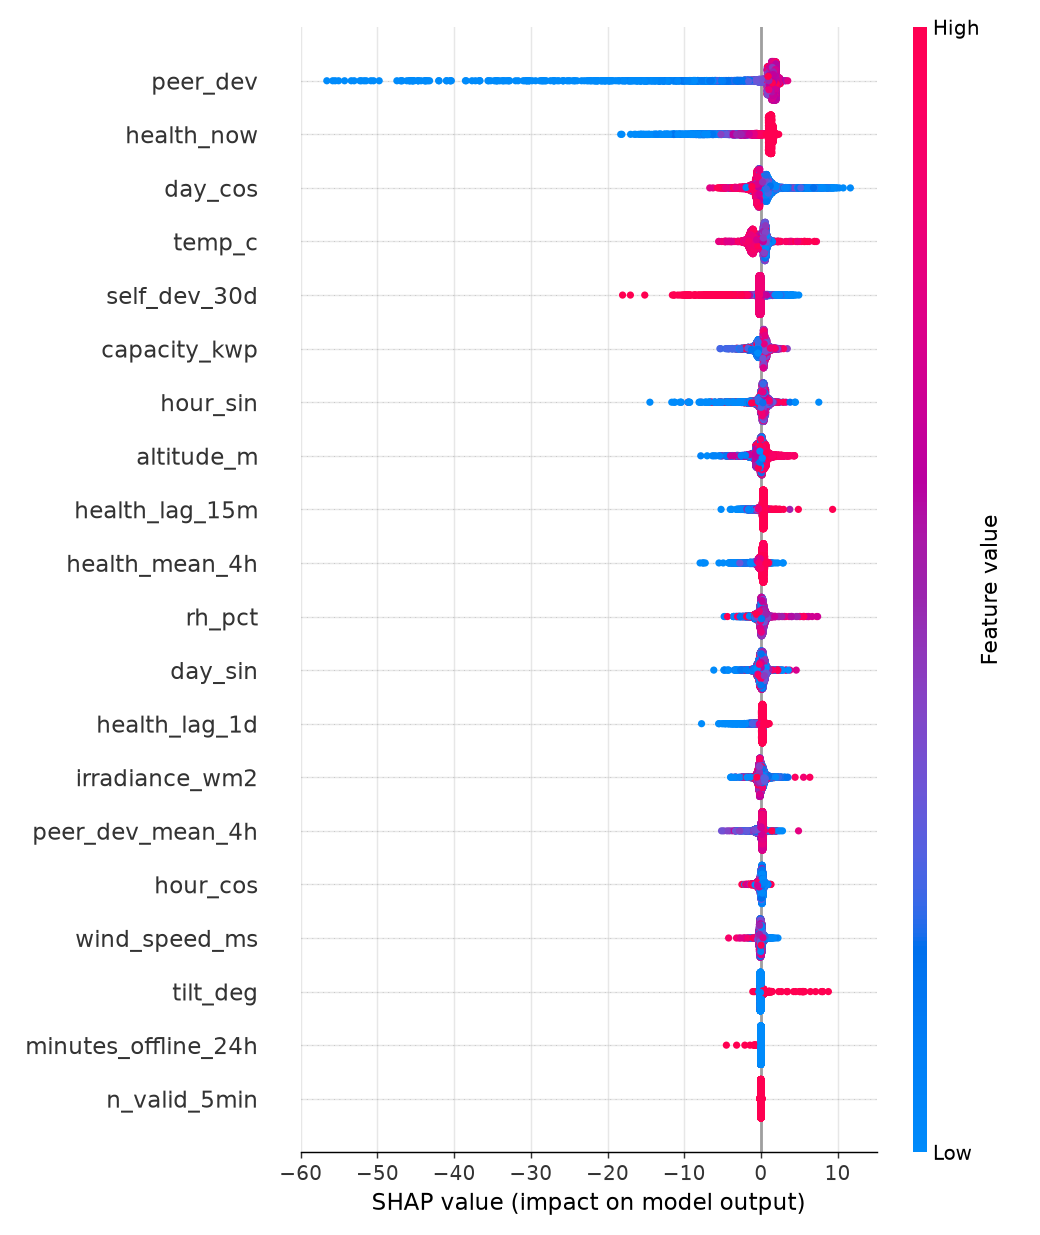

In [11]:
show("xgb_shap_summary")

**Finding.** A low peer deviation (blue, the inverter doing worse than the rest of the campus right now) pulls the forecast down by up to 55 points: the strongest single effect. Low current health also pulls it down. A high 30-day self deviation (doing better than usual) pulls it down slightly: unusually good values tend to return to normal. This matches the permutation importance.